import 

In [1]:
# Install scVelo (it also installs scanpy).
%pip install -q scvelo


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Hide harmless warning messages.
import warnings
warnings.filterwarnings('ignore')

# Never print warning messages, even if a package switches them back on.
warnings.showwarning = lambda *args, **kwargs: None

# Packages for numbers and plots.
import numpy
import matplotlib.pyplot

# Packages for single-cell analysis and RNA velocity.
import scanpy
import scvelo

# Plot settings.
scvelo.settings.set_figure_params(dpi=80, facecolor='white')

In [3]:
# Print the versions we use.
from importlib.metadata import version

print('scvelo  version:', version('scvelo'))
print('scanpy  version:', version('scanpy'))
print('pandas  version:', version('pandas'))

scvelo  version: 0.3.4
scanpy  version: 1.12.4
pandas  version: 3.0.5


load data

In [4]:
# Download the pancreas data (about 50 MB) and read it.
adata = scvelo.datasets.pancreas()

# Summary of the data.
print(adata)

100%|██████████| 50.0M/50.0M [00:04<00:00, 11.3MB/s]


AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: 'spliced', 'unspliced', None (.X)


In [5]:
# Total spliced and unspliced counts in the whole dataset.
total_spliced = adata.layers['spliced'].sum()
total_unspliced = adata.layers['unspliced'].sum()

# Fraction of all counts that is unspliced.
fraction = total_unspliced / (total_spliced + total_unspliced)

print('fraction of counts that is unspliced:', round(fraction, 3))

fraction of counts that is unspliced: 0.163


prepare the data 

In [6]:
# Step 1: filter genes and normalize the spliced and unspliced layers.
scvelo.pp.filter_and_normalize(adata, min_shared_counts=20)

# Step 2: log-transform.
scanpy.pp.log1p(adata)

# Step 3: keep the 2,000 most variable genes.
scanpy.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)

print('cells x genes now:', adata.shape)

Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
cells x genes now: (3696, 2000)


In [7]:
# Average every cell with its neighbors.
scvelo.pp.moments(adata, n_pcs=None, n_neighbors=None)

# The new smoothed layers.
print(list(adata.layers.keys()))

or is corrupted (e.g. due to subsetting). Consider recomputing with `pp.neighbors`.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
['spliced', 'unspliced', None, 'Ms', 'Mu']


phase portrait by hand 

In [8]:
# The gene we study, Pcsk2
gene = 'Pcsk2'     # <-- change me (try 'Cpe', 'Gnao1', 'Ins2', 'Adk')

# Smoothed spliced (s) and unspliced (u) values of this gene, one per cell.
s = adata[:, gene].layers['Ms'].flatten()
u = adata[:, gene].layers['Mu'].flatten()

print('number of cells:', len(s))

number of cells: 3696


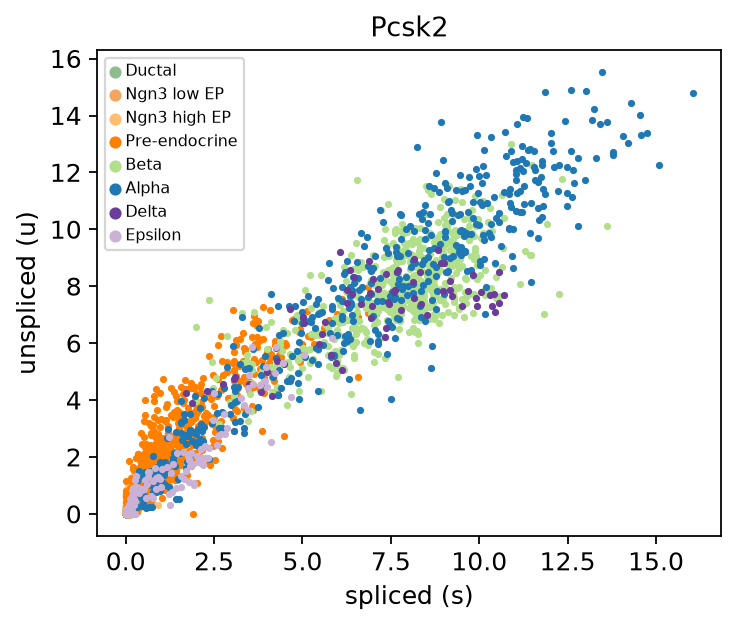

In [9]:
# The cell types and their colors.
cell_types = adata.obs['clusters'].cat.categories
colors = adata.uns['clusters_colors']

matplotlib.pyplot.figure(figsize=(5, 4))

# Draw the cells of each cell type in its own color.
for i in range(len(cell_types)):
    is_this_type = (adata.obs['clusters'] == cell_types[i]).values
    matplotlib.pyplot.scatter(s[is_this_type], u[is_this_type],
                              s=5, color=colors[i], label=cell_types[i])

matplotlib.pyplot.xlabel('spliced (s)')
matplotlib.pyplot.ylabel('unspliced (u)')
matplotlib.pyplot.title(gene)
matplotlib.pyplot.legend(fontsize=7, markerscale=2)
matplotlib.pyplot.show()

line steady state

In [10]:
# The 5% of cells with the lowest and the highest spliced values.
low_cut = numpy.percentile(s, 5)
high_cut = numpy.percentile(s, 95)
extreme = (s <= low_cut) | (s >= high_cut)

print('cells used for the fit:', extreme.sum())

# Slope of the line through the origin, fitted on those cells.
gamma = (u[extreme] * s[extreme]).sum() / (s[extreme] * s[extreme]).sum()

print('gamma fitted by hand:', round(gamma, 3))

cells used for the fit: 1500
gamma fitted by hand: 0.964


In [11]:
# The 5% of cells with the lowest and the highest spliced values.
low_cut = numpy.percentile(s, 5)
high_cut = numpy.percentile(s, 95)
extreme = (s <= low_cut) | (s >= high_cut)

print('cells used for the fit:', extreme.sum())

# Slope of the line through the origin, fitted on those cells.
gamma = (u[extreme] * s[extreme]).sum() / (s[extreme] * s[extreme]).sum()

print('gamma fitted by hand:', round(gamma, 3))

cells used for the fit: 1500
gamma fitted by hand: 0.964


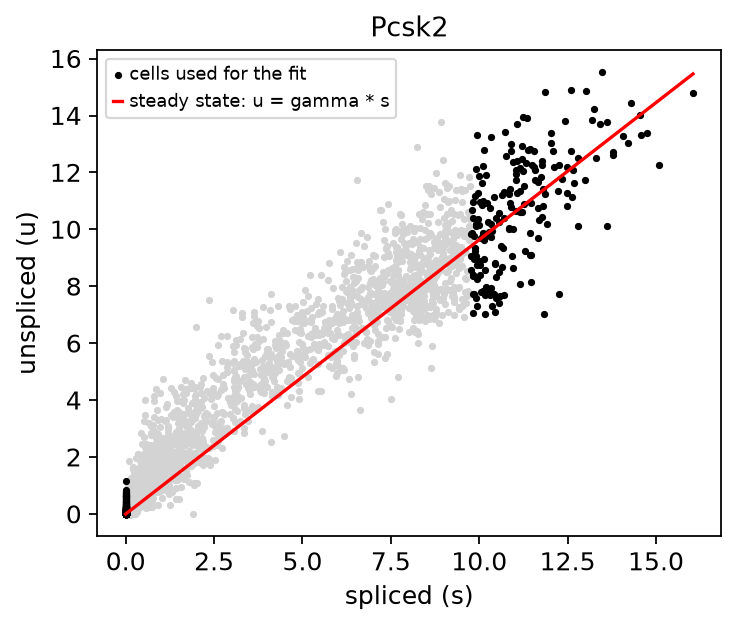

In [13]:
matplotlib.pyplot.figure(figsize=(5, 4))

# All cells in grey, the cells used for the fit in black.
matplotlib.pyplot.scatter(s, u, s=5, color='lightgrey')
matplotlib.pyplot.scatter(s[extreme], u[extreme], s=5, color='black', label='cells used for the fit')

# The steady-state line u = gamma * s.
x_line = numpy.linspace(0, s.max(), 50)
matplotlib.pyplot.plot(x_line, gamma * x_line, color='red', label='steady state: u = gamma * s')

matplotlib.pyplot.xlabel('spliced (s)')
matplotlib.pyplot.ylabel('unspliced (u)')
matplotlib.pyplot.title(gene)
matplotlib.pyplot.legend(fontsize=8)
matplotlib.pyplot.show()

velocity by hand 

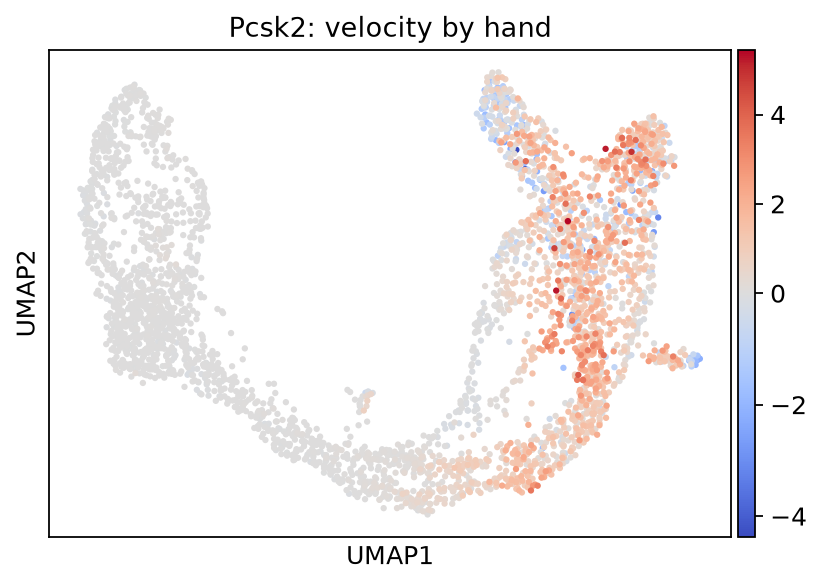

In [12]:
# Velocity of the gene in every cell.
velocity_by_hand = u - gamma * s

# Store it in adata.obs so we can colour the UMAP with it.
adata.obs['velocity_by_hand'] = velocity_by_hand

# Red = positive (switching on), blue = negative (switching off).
scanpy.pl.umap(adata, color='velocity_by_hand', cmap='coolwarm',
               vcenter=0, title=gene + ': velocity by hand')

pipeline approch 

In [26]:
from pathlib import Path

results_dir = Path("results/modul4")
results_dir.mkdir(exist_ok=True)

In [29]:
def analyze_gene(gene):

    # Get smoothed spliced and unspliced values
    s = adata[:, gene].layers['Ms'].flatten()
    u = adata[:, gene].layers['Mu'].flatten()

    # Fit the steady-state line using the lowest and highest 5%
    low_cut = numpy.percentile(s, 5)
    high_cut = numpy.percentile(s, 95)
    extreme = (s <= low_cut) | (s >= high_cut)

    gamma = (u[extreme] * s[extreme]).sum() / (
        s[extreme] * s[extreme]
    ).sum()

    print(gene, 'gamma =', round(gamma, 3))

    # Phase portrait
    matplotlib.pyplot.figure(figsize=(5, 5))

    for i in range(len(cell_types)):
        is_this_type = (adata.obs['clusters'] == cell_types[i]).values
        matplotlib.pyplot.scatter(
            s[is_this_type],
            u[is_this_type],
            s=5,
            color=colors[i],
            label=cell_types[i]
        )

    # Same range on x and y axes
    max_value = max(s.max(), u.max())

    # Steady-state line
    x = numpy.linspace(0, max_value, 100)
    matplotlib.pyplot.plot(x, gamma * x, color='black')

    matplotlib.pyplot.xlabel('spliced (s)')
    matplotlib.pyplot.ylabel('unspliced (u)')
    matplotlib.pyplot.title(gene)
    matplotlib.pyplot.xlim(0, max_value)
    matplotlib.pyplot.ylim(0, max_value)
    matplotlib.pyplot.gca().set_aspect('equal', adjustable='box')
    matplotlib.pyplot.legend(fontsize=7, markerscale=2)

    # SAVE PHASE PORTRAIT
    matplotlib.pyplot.savefig(
        results_dir / f"{gene}_phase_portrait.png",
        dpi=300,
        bbox_inches='tight'
    )

    matplotlib.pyplot.show()

    # Calculate velocity by hand
    velocity = u - gamma * s

    # Keep a separate velocity column for each gene
    adata.obs['velocity_' + gene] = velocity

    # UMAP coloured by hand-calculated velocity
    scanpy.pl.umap(
        adata,
        color='velocity_' + gene,
        cmap='coolwarm',
        vcenter=0,
        title=gene + ': velocity by hand',
        show=False
    )

    # SAVE VELOCITY UMAP
    matplotlib.pyplot.savefig(
        results_dir / f"{gene}_velocity_umap.png",
        dpi=300,
        bbox_inches='tight'
    )

    matplotlib.pyplot.show()

Pcsk2 gamma = 0.964


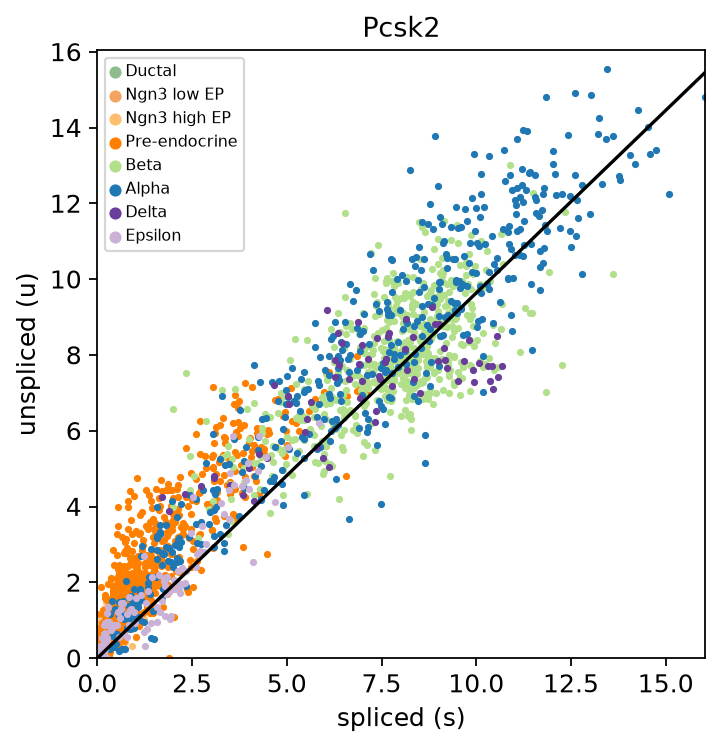

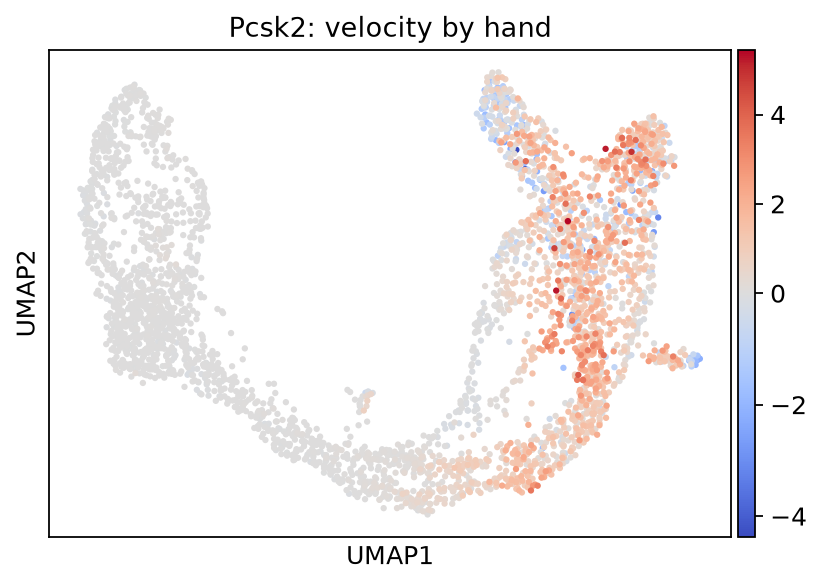

Adk gamma = 0.756


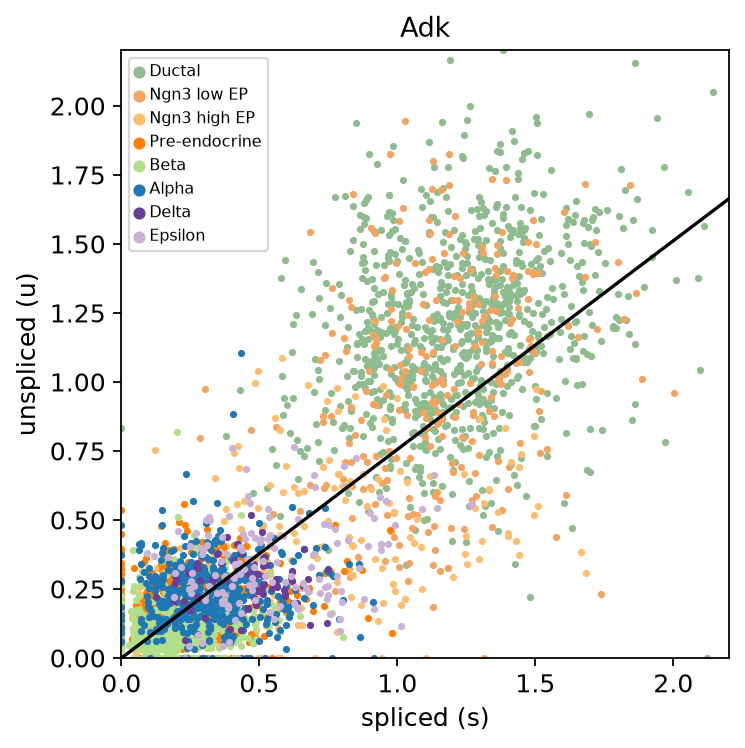

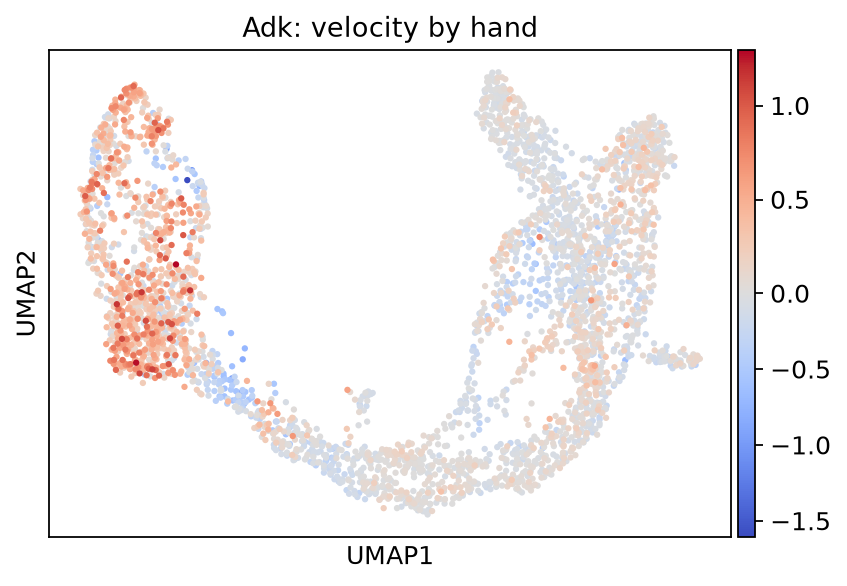

Cpe gamma = 0.093


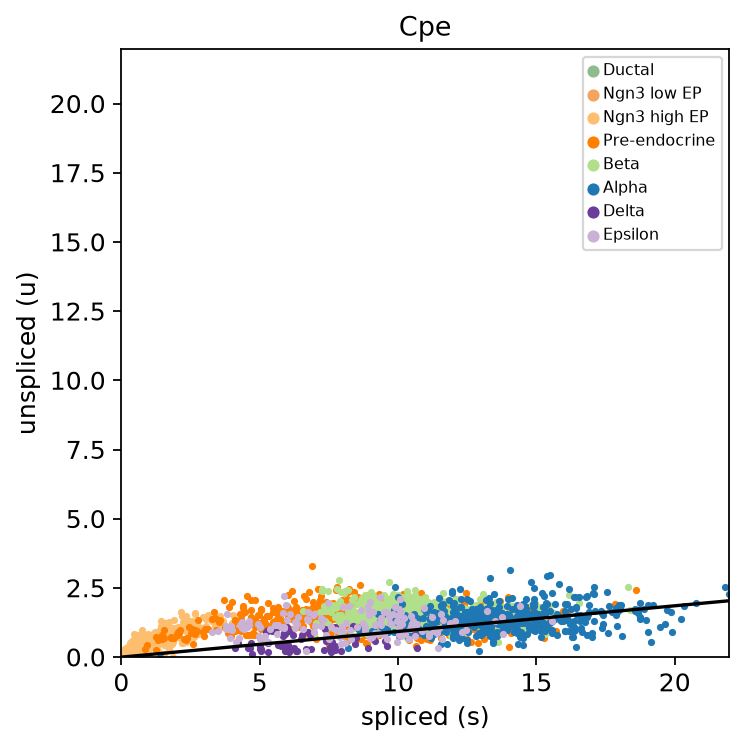

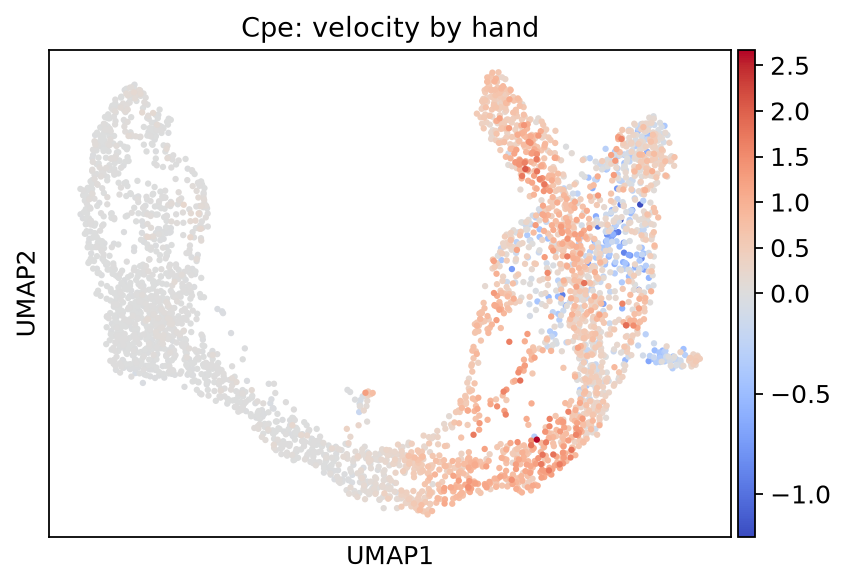

Gnao1 gamma = 1.994


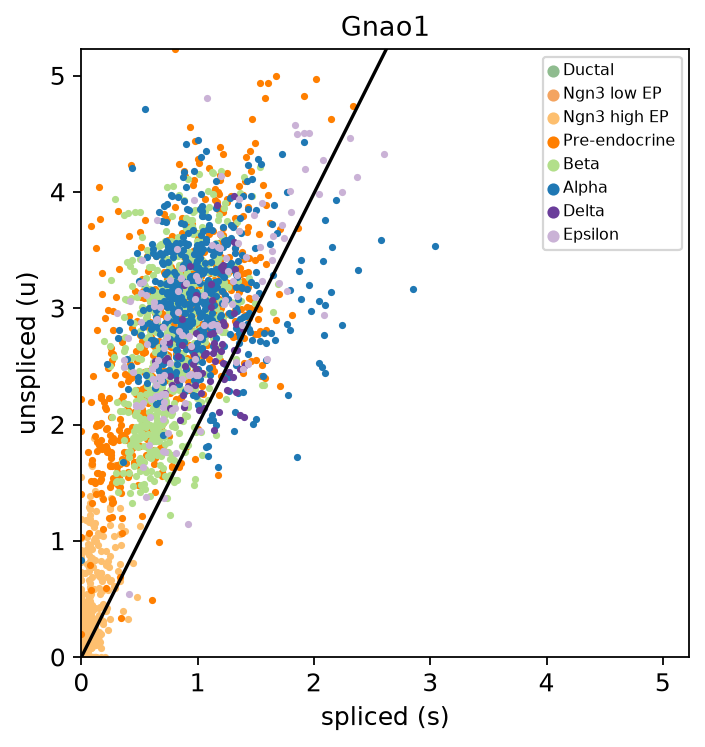

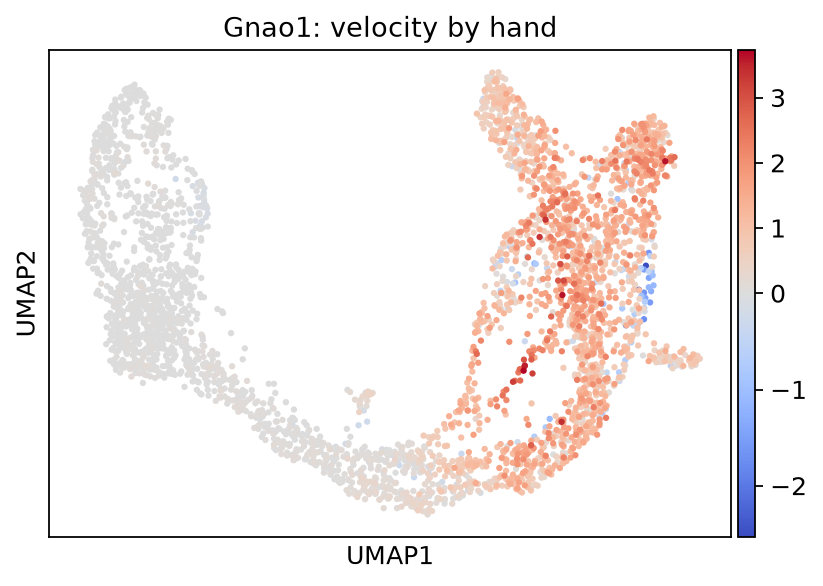

Ins2 gamma = 2.681


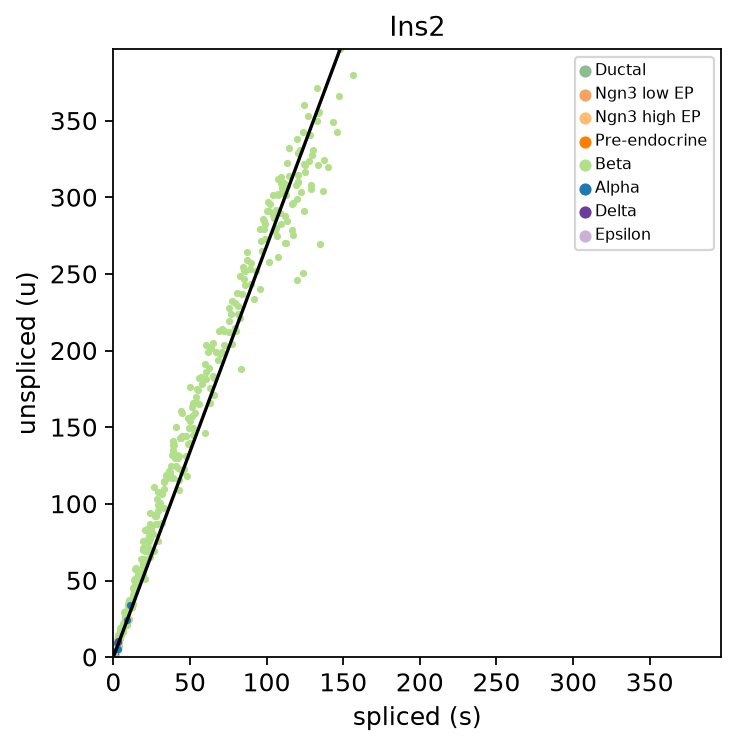

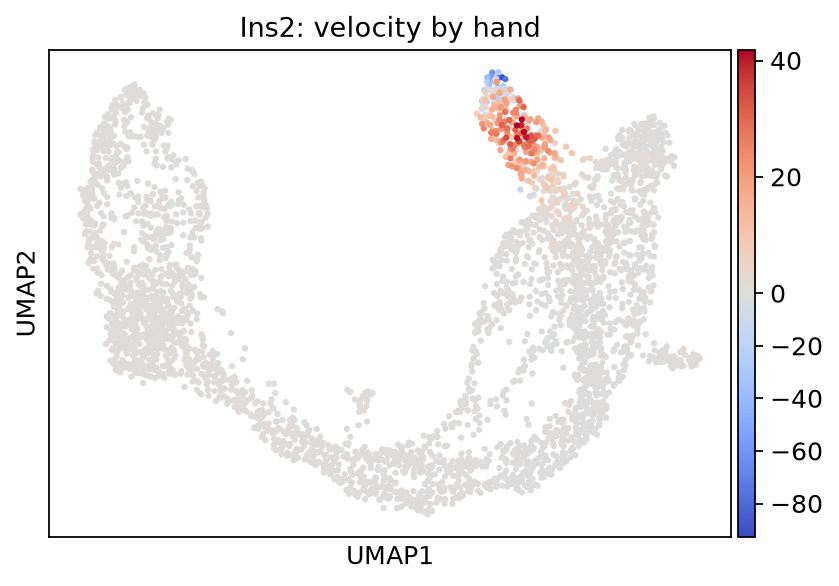

In [30]:
for gene in ['Pcsk2','Adk', 'Cpe', 'Gnao1', 'Ins2']:
    analyze_gene(gene)